In [1]:
%pip install -q numpy pandas matplotlib scikit-learn

1.Import Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
np.random.seed(42)

2.Create/Load an Appropriate Dataset

In [3]:
#Generate a reproducible non-linear dataset
X = np.linspace(0, 10, 100)
y = np.sin(X) + np.random.normal(0, 0.15, size=len(X))

data = pd.DataFrame({'X': X, 'Y': y})

display(data.head())
print("Number of observations:", len(data))

,X,Y
0,0.00000,0.074507
1,0.10101,0.080099
2,0.20202,0.297802
3,0.30303,0.526868
4,0.40404,0.358014


Number of observations: 100


3.Visualize the Original Data

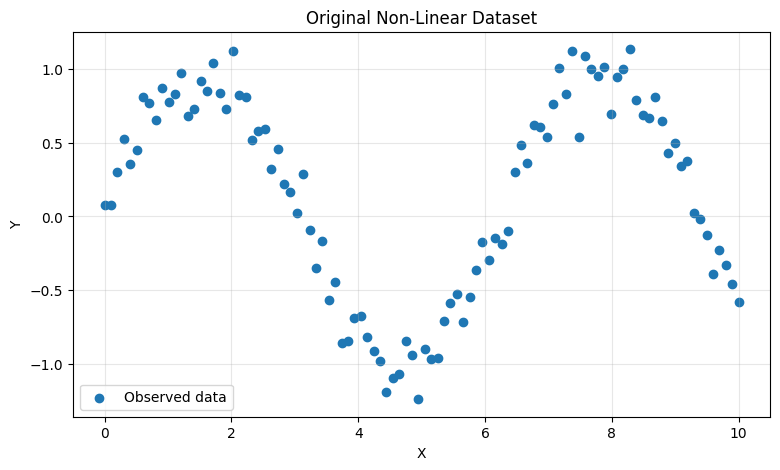

In [5]:
plt.figure(figsize=(9, 5))
plt.scatter(X, y, label='Observed data')
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Original Non-Linear Dataset')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

4.Implement Locally Weighted Regression

In [6]:
def locally_weighted_regression(x_train, y_train, x_query, tau=0.5):
  x_train = np.asarray(x_train, dtype=float).reshape(-1)
  y_train = np.asarray(x_train, dtype=float).reshape(-1)

  #Design matrix for local linear regression
  X_design = np.column_stack((np.ones(len(x_train)), x_train))

  #Gaussian weights
  weights = np.exp(-((x_train - x_query) ** 2) / (2 * tau ** 2))
  W = np.diag(weights)

  #Weighted least squares
  A = X_design.T @ W @ X_design
  B = X_design.T @ W @ y_train

  #Pseudo-inverse makes the implementation numerically safer
  theta = np.linalg.pinv(A) @ B

  #Prediction at query point
  x_query_design = np.array([1.0, x_query])

  return float(x_query_design @ theta)


5.Fit the LWR Model

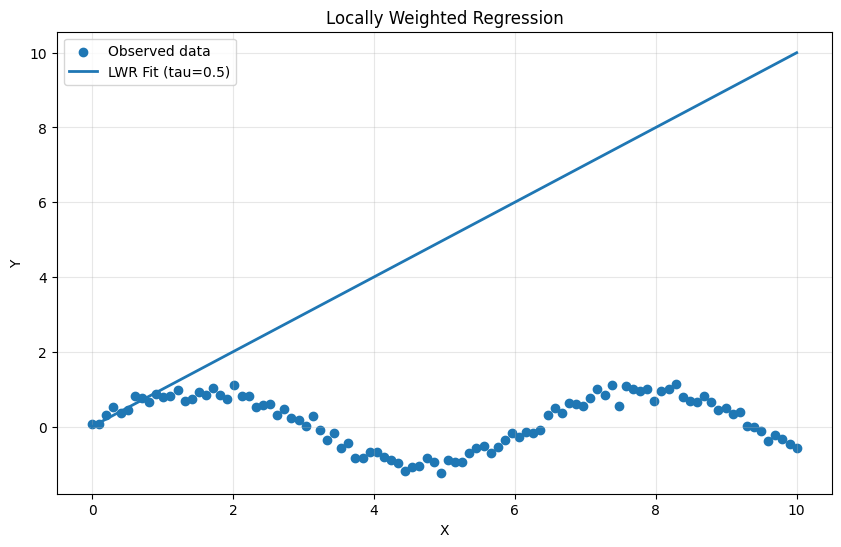

In [7]:
tau = 0.5

x_test = np.linspace(X.min(), X.max(), 400)

y_lwr = np.array([
    locally_weighted_regression(X, y, xq, tau = tau)
    for xq in x_test
])

plt.figure(figsize=(10, 6))
plt.scatter(X, y, label="Observed data")
plt.plot(x_test, y_lwr, linewidth=2, label=f"LWR Fit (tau={tau})")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Locally Weighted Regression")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

6.Compare different bandwidth values

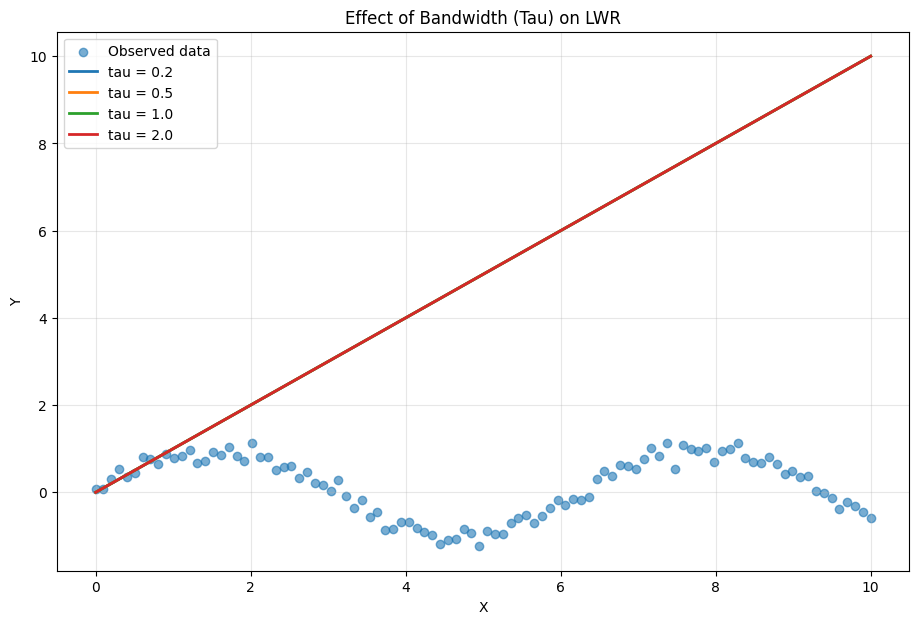

In [8]:
taus = [0.2, 0.5, 1.0, 2.0]

plt.figure(figsize=(11, 7))
plt.scatter(X, y, label="Observed data", alpha=0.6)

for tau_value in taus:
  y_fit = np.array([
      locally_weighted_regression(X, y, xq, tau = tau_value)
      for xq in x_test
  ])
  plt.plot(x_test, y_fit, linewidth=2, label=f"tau = {tau_value}")

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Effect of Bandwidth (Tau) on LWR")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

7.Compare LWR with Ordinary Linear Regression

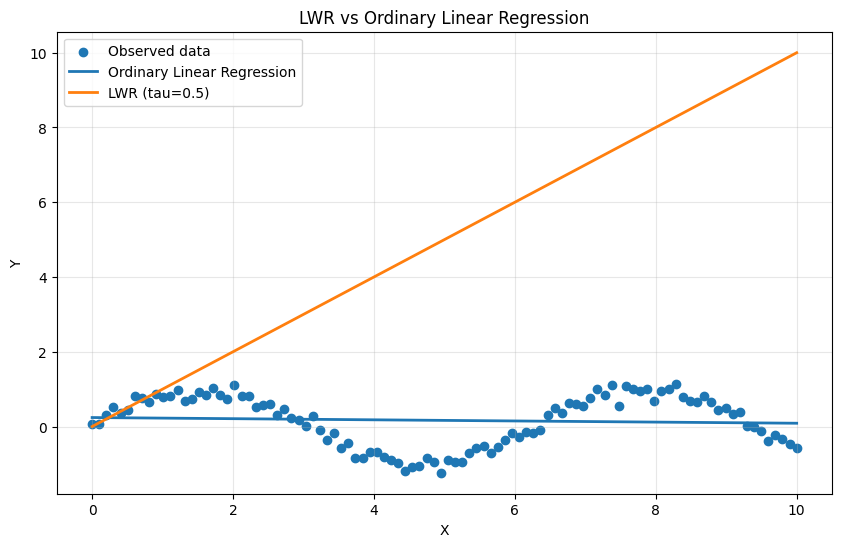

In [9]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()
linear_model.fit(X.reshape(-1, 1), y)

y_linear = linear_model.predict(x_test.reshape(-1, 1))

plt.figure(figsize=(10, 6))
plt.scatter(X, y, label="Observed data")
plt.plot(x_test, y_linear, linewidth=2, label="Ordinary Linear Regression")
plt.plot(x_test, y_lwr, linewidth=2, label=f"LWR (tau={tau})")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("LWR vs Ordinary Linear Regression")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

8.Evaluate the LWR Model

In [12]:
y_pred_training = np.array([
    locally_weighted_regression(X, y, xq, tau = tau)
    for xq in X
])

mse_lwr = mean_squared_error(y, y_pred_training)
r2_lwr = r2_score(y, y_pred_training)

y_linaer_training = linear_model.predict(X.reshape(-1, 1))
mse_linear = mean_squared_error(y, y_linaer_training)
r2_linear = r2_score(y, y_linaer_training)

results = pd.DataFrame({
    "Model": ["Locally Weighted Regression", "Ordinary Linear Regression"],
    "MSE": [mse_lwr, mse_linear],
    "R2 Score": [r2_lwr, r2_linear]
})

display(results)

,Model,MSE,R2 Score
0,Locally Weighted Regression,32.611322,-69.891521
1,Ordinary Linear Regression,0.458044,0.004288


9.Demonstrate Prediction for a New Query Point

In [13]:
query_points = [2.0, 5.0, 8.0]

prediction_table = pd.DataFrame({
    "Query X": query_points,
    "LWR Prediction": [
        locally_weighted_regression(X, y, q, tau = tau)
        for q in query_points
    ]
})

display(prediction_table)

,Query X,LWR Prediction
0,2.0,2.0
1,5.0,5.0
2,8.0,8.0
